# Project 44: Customer Retention Prediction

**Course:** INT315 - Cluster Computing | **Assessment:** CA2  
**Student Name:** Parth Tripathi | **Registration No.:** 12306364 | **Section:** RK2M2348  
**Faculty:** Dr. Rajinder Vir | **School:** School of Computer Science and Engineering, Lovely Professional University  

---

Enterprise Big Data Analytics Platform analyzing 1,000 customer transaction schedules,
11 behavioral attributes, 7 location hubs, and 3 membership tiers using Decision Tree
Classification and PySpark ML Pipeline.

---

### Execution Tasks

| Task | Description |
|------|-------------|
| Task 1 | Load customer transaction history into Spark DataFrame |
| Task 2 | Handle missing order frequency and value details |
| Task 3 | Encode categorical fields (location, membership type, gender) |
| Task 4 | Train a Decision Tree classifier to predict churn or retention |
| Task 5 | Evaluate using accuracy, precision, and recall |
| Task 6 | Visualize retention rates across different membership levels |

**Dataset:** customer_data.csv


---
## Environment Setup & Library Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 200)

print("Libraries loaded successfully.")

Libraries loaded successfully.


---
## Task 1: Load Customer Transaction History

Objective: Read the CSV dataset, inspect structure, data types, nulls, and summary statistics.

### PySpark Equivalent Code:
```python
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("Task1_LoadData") \
    .master("local[*]") \
    .getOrCreate()

df = spark.read.csv("customer_data.csv", header=True, inferSchema=True)
df.printSchema()
df.show(5)
```

In [2]:
df = pd.read_csv('customer_data.csv')

print("=" * 60)
print("TASK 1: LOAD CUSTOMER TRANSACTION HISTORY")
print("=" * 60)
print(f"Total Records: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")
print(f"Column Names: {list(df.columns)}")

TASK 1: LOAD CUSTOMER TRANSACTION HISTORY
Total Records: 1000
Total Columns: 11
Column Names: ['customer_id', 'location', 'membership_type', 'order_frequency', 'total_order_value', 'avg_order_value', 'days_since_last_order', 'customer_age', 'gender', 'satisfaction_score', 'churn']


In [3]:
print("Schema / Column Summary:")
schema_info = pd.DataFrame({
    'Column': df.columns,
    'Data Type': df.dtypes.values,
    'Non-Null Count': df.count().values,
    'Null Count': df.isnull().sum().values
})
schema_info

Schema / Column Summary:


,Column,Data Type,Non-Null Count,Null Count
0,customer_id,int64,1000,0
1,location,object,1000,0
2,membership_type,object,1000,0
3,order_frequency,float64,950,50
4,total_order_value,float64,960,40
5,avg_order_value,float64,1000,0
6,days_since_last_order,int64,1000,0
7,customer_age,int64,1000,0
8,gender,object,1000,0
9,satisfaction_score,int64,1000,0


In [4]:
print("First 10 Rows:")
df.head(10)

First 10 Rows:


,customer_id,location,membership_type,order_frequency,total_order_value,avg_order_value,days_since_last_order,customer_age,gender,satisfaction_score,churn
0,1,Pune,Bronze,34.0,30141.01,886.50,234,35,Male,5,1
1,2,Chennai,Bronze,NaN,3692.32,111.89,28,52,Male,3,0
2,3,Kolkata,Bronze,21.0,43923.35,2091.59,11,43,Female,5,0
3,4,Pune,Gold,17.0,43924.46,2583.79,206,33,Female,3,0
4,5,Bangalore,Bronze,22.0,16855.20,766.15,167,23,Male,2,1
5,6,Kolkata,Silver,48.0,17350.09,361.46,247,61,Female,3,1
6,7,Kolkata,Silver,37.0,49456.90,1336.67,47,60,Male,2,0
7,8,Pune,Silver,15.0,31495.72,2099.71,246,64,Male,2,0
8,9,Delhi,Bronze,35.0,NaN,765.72,127,64,Female,4,0
9,10,Bangalore,Silver,28.0,41988.53,1499.59,147,59,Female,2,0


In [5]:
print("Summary Statistics:")
df.describe().round(2)

Summary Statistics:


,customer_id,order_frequency,total_order_value,avg_order_value,days_since_last_order,customer_age,satisfaction_score,churn
count,1000.00,950.00,960.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,500.50,24.59,25630.72,2235.40,186.79,41.63,3.02,0.36
std,288.82,13.76,14200.19,4065.27,102.49,13.56,1.42,0.48
min,1.00,1.00,521.92,13.33,1.00,18.00,1.00,0.00
25%,250.75,13.00,13261.28,558.94,99.00,30.00,2.00,0.00
50%,500.50,24.00,26112.18,1049.16,192.00,42.00,3.00,0.00
75%,750.25,36.00,38116.15,2090.31,271.25,53.00,4.00,1.00
max,1000.00,49.00,49985.83,45065.90,364.00,64.00,5.00,1.00


---
## Task 2: Handle Missing Values in Order Frequency and Order Value

Objective: Identify null values in order_frequency and total_order_value, and substitute them with column means.

### PySpark Equivalent Code:
```python
from pyspark.sql.functions import mean, col, isnan, isnull

mean_freq = df.select(mean("order_frequency")).collect()[0][0]
mean_value = df.select(mean("total_order_value")).collect()[0][0]
df_clean = df.fillna({"order_frequency": mean_freq, "total_order_value": mean_value})
```

In [6]:
print("=" * 60)
print("TASK 2: HANDLE MISSING VALUES")
print("=" * 60)

print("Missing Values BEFORE Handling:")
missing_before = df.isnull().sum()
missing_before = missing_before[missing_before > 0]
for col_name, count in missing_before.items():
    print(f"  {col_name}: {count} missing")

mean_freq = df['order_frequency'].mean()
mean_value = df['total_order_value'].mean()
print(f"\nCalculated Mean order_frequency:   {mean_freq:.2f}")
print(f"Calculated Mean total_order_value: {mean_value:.2f}")

df['order_frequency'] = df['order_frequency'].fillna(mean_freq)
df['total_order_value'] = df['total_order_value'].fillna(mean_value)

print("\nMissing Values AFTER Handling:")
missing_after = df.isnull().sum()
print(f"Total null cells remaining: {missing_after.sum()}")

TASK 2: HANDLE MISSING VALUES
Missing Values BEFORE Handling:
  order_frequency: 50 missing
  total_order_value: 40 missing

Calculated Mean order_frequency:   24.59
Calculated Mean total_order_value: 25630.72

Missing Values AFTER Handling:
Total null cells remaining: 0


In [7]:
print("Cleaned Data Preview (first 10 rows):")
df.head(10)

Cleaned Data Preview (first 10 rows):


,customer_id,location,membership_type,order_frequency,total_order_value,avg_order_value,days_since_last_order,customer_age,gender,satisfaction_score,churn
0,1,Pune,Bronze,34.000000,30141.010000,886.50,234,35,Male,5,1
1,2,Chennai,Bronze,24.592632,3692.320000,111.89,28,52,Male,3,0
2,3,Kolkata,Bronze,21.000000,43923.350000,2091.59,11,43,Female,5,0
3,4,Pune,Gold,17.000000,43924.460000,2583.79,206,33,Female,3,0
4,5,Bangalore,Bronze,22.000000,16855.200000,766.15,167,23,Male,2,1
5,6,Kolkata,Silver,48.000000,17350.090000,361.46,247,61,Female,3,1
6,7,Kolkata,Silver,37.000000,49456.900000,1336.67,47,60,Male,2,0
7,8,Pune,Silver,15.000000,31495.720000,2099.71,246,64,Male,2,0
8,9,Delhi,Bronze,35.000000,25630.722125,765.72,127,64,Female,4,0
9,10,Bangalore,Silver,28.000000,41988.530000,1499.59,147,59,Female,2,0


---
## Task 3: Encode Categorical Fields

Objective: Convert categorical columns (location, membership_type, gender) into numeric representations using LabelEncoder / StringIndexer.

### PySpark Equivalent Code:
```python
from pyspark.ml.feature import StringIndexer

categorical_cols = ["location", "membership_type", "gender"]
for col_name in categorical_cols:
    indexer = StringIndexer(inputCol=col_name, outputCol=col_name + "_index")
    df = indexer.fit(df).transform(df)
```

In [8]:
print("=" * 60)
print("TASK 3: ENCODE CATEGORICAL FIELDS")
print("=" * 60)

le_location = LabelEncoder()
le_membership = LabelEncoder()
le_gender = LabelEncoder()

df['location_encoded'] = le_location.fit_transform(df['location'])
df['membership_encoded'] = le_membership.fit_transform(df['membership_type'])
df['gender_encoded'] = le_gender.fit_transform(df['gender'])

print("Location Mapping:")
print(df[['location', 'location_encoded']].drop_duplicates().sort_values('location_encoded').to_string(index=False))

print("\nMembership Mapping:")
print(df[['membership_type', 'membership_encoded']].drop_duplicates().sort_values('membership_encoded').to_string(index=False))

print("\nGender Mapping:")
print(df[['gender', 'gender_encoded']].drop_duplicates().sort_values('gender_encoded').to_string(index=False))

TASK 3: ENCODE CATEGORICAL FIELDS
Location Mapping:
 location  location_encoded
Bangalore                 0
  Chennai                 1
    Delhi                 2
Hyderabad                 3
  Kolkata                 4
   Mumbai                 5
     Pune                 6

Membership Mapping:
membership_type  membership_encoded
         Bronze                   0
           Gold                   1
         Silver                   2

Gender Mapping:
gender  gender_encoded
Female               0
  Male               1


In [9]:
print("Sample Encoded Records:")
df[['customer_id', 'location', 'location_encoded',
    'membership_type', 'membership_encoded',
    'gender', 'gender_encoded']].head(10)

Sample Encoded Records:


,customer_id,location,location_encoded,membership_type,membership_encoded,gender,gender_encoded
0,1,Pune,6,Bronze,0,Male,1
1,2,Chennai,1,Bronze,0,Male,1
2,3,Kolkata,4,Bronze,0,Female,0
3,4,Pune,6,Gold,1,Female,0
4,5,Bangalore,0,Bronze,0,Male,1
5,6,Kolkata,4,Silver,2,Female,0
6,7,Kolkata,4,Silver,2,Male,1
7,8,Pune,6,Silver,2,Male,1
8,9,Delhi,2,Bronze,0,Female,0
9,10,Bangalore,0,Silver,2,Female,0


---
## Task 4: Train Decision Tree Classifier

Objective: Build and train a Decision Tree model on an 80/20 train-test split to predict customer churn.

### PySpark Equivalent Code:
```python
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import DecisionTreeClassifier

assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
df = assembler.transform(df)

train_data, test_data = df.randomSplit([0.8, 0.2], seed=42)
dt = DecisionTreeClassifier(labelCol="churn", featuresCol="features", maxDepth=5)
model = dt.fit(train_data)
predictions = model.transform(test_data)
```

In [10]:
print("=" * 60)
print("TASK 4: TRAIN DECISION TREE CLASSIFIER")
print("=" * 60)

feature_cols = ['order_frequency', 'total_order_value', 'avg_order_value',
                'days_since_last_order', 'customer_age', 'satisfaction_score',
                'location_encoded', 'membership_encoded', 'gender_encoded']

X = df[feature_cols]
y = df['churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training instances: {len(X_train)}")
print(f"Test instances:     {len(X_test)}")

model = DecisionTreeClassifier(max_depth=5, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Model trained successfully.")

TASK 4: TRAIN DECISION TREE CLASSIFIER
Training instances: 800
Test instances:     200
Model trained successfully.


In [11]:
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': model.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)
importance_df.index = importance_df.index + 1

print("Feature Importances:")
importance_df

Feature Importances:


,Feature,Importance
1,order_frequency,0.188637
2,days_since_last_order,0.179542
3,avg_order_value,0.159232
4,satisfaction_score,0.148475
5,total_order_value,0.114407
6,customer_age,0.088959
7,membership_encoded,0.087401
8,location_encoded,0.033346
9,gender_encoded,0.000000


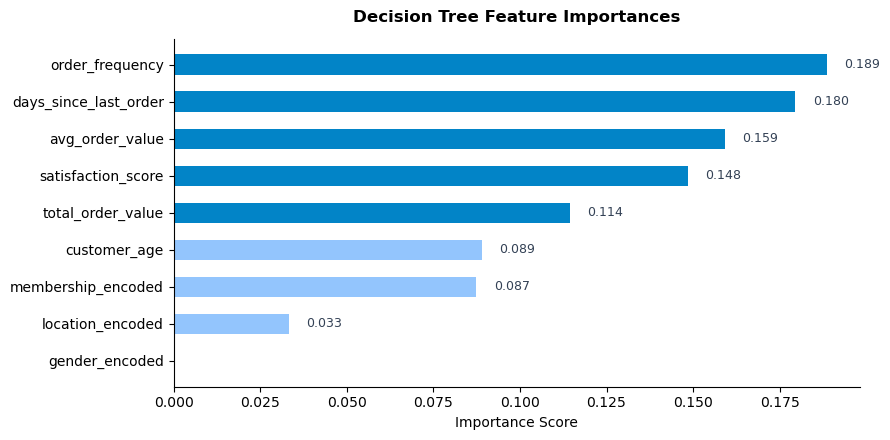

In [12]:
imp_sorted = importance_df.sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ['#0284c7' if v > 0.1 else '#93c5fd' for v in imp_sorted['Importance']]
bars = ax.barh(imp_sorted['Feature'], imp_sorted['Importance'], color=colors, height=0.55)

for bar, val in zip(bars, imp_sorted['Importance']):
    if val > 0.01:
        ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
                f'{val:.3f}', va='center', fontsize=9, color='#334155')

ax.set_xlabel('Importance Score', fontsize=10)
ax.set_title('Decision Tree Feature Importances', fontsize=12, fontweight='bold', pad=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

---
## Task 5: Model Evaluation

Objective: Evaluate performance using Accuracy, Precision, Recall, and Confusion Matrix.

### PySpark Equivalent Code:
```python
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

evaluator_acc = MulticlassClassificationEvaluator(
    labelCol="churn", predictionCol="prediction", metricName="accuracy")
accuracy = evaluator_acc.evaluate(predictions)
```

In [13]:
print("=" * 60)
print("TASK 5: MODEL EVALUATION")
print("=" * 60)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='weighted')
rec = recall_score(y_test, y_pred, average='weighted')

print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Retained (0)', 'Churned (1)']))

TASK 5: MODEL EVALUATION
Accuracy:  0.6400
Precision: 0.6275
Recall:    0.6400

Classification Report:
              precision    recall  f1-score   support

Retained (0)       0.68      0.78      0.73       123
 Churned (1)       0.54      0.42      0.47        77

    accuracy                           0.64       200
   macro avg       0.61      0.60      0.60       200
weighted avg       0.63      0.64      0.63       200



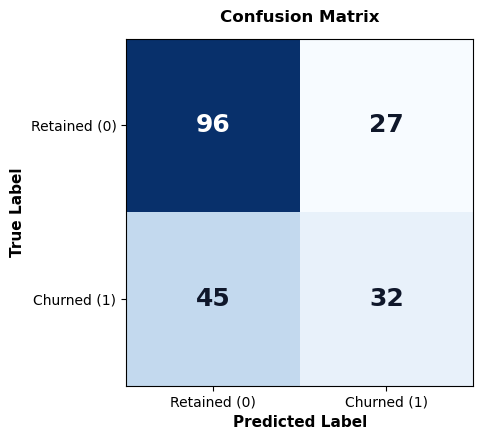

In [14]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Retained (0)', 'Churned (1)'], fontsize=10)
ax.set_yticklabels(['Retained (0)', 'Churned (1)'], fontsize=10)
ax.set_xlabel('Predicted Label', fontsize=11, fontweight='bold')
ax.set_ylabel('True Label', fontsize=11, fontweight='bold')
ax.set_title('Confusion Matrix', fontsize=12, fontweight='bold', pad=12)

for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                fontsize=18, fontweight='bold',
                color='white' if cm[i, j] > cm.max()/2 else '#0f172a')

plt.tight_layout()
plt.show()

---
## Task 6: Visualize Retention Rates Across Membership Levels

Objective: Compute and visualize customer retention rates by membership tier (Gold, Silver, Bronze).

### PySpark Equivalent Code:
```python
from pyspark.sql.functions import mean

retention_df = df.groupBy("membership_type").agg(
    mean("churn").alias("churn_rate")
).toPandas()
retention_df["retention_rate"] = 1 - retention_df["churn_rate"]
```

In [15]:
print("=" * 60)
print("TASK 6: VISUALIZE RETENTION RATES")
print("=" * 60)

retention = df.groupby('membership_type')['churn'].agg(['mean', 'count']).reset_index()
retention.columns = ['Membership Type', 'Churn Rate', 'Total Customers']
retention['Retention Rate'] = 1 - retention['Churn Rate']
retention = retention.sort_values('Membership Type')

display_ret = retention.copy()
display_ret['Churn Rate'] = display_ret['Churn Rate'].apply(lambda x: f"{x:.2%}")
display_ret['Retention Rate'] = display_ret['Retention Rate'].apply(lambda x: f"{x:.2%}")
display_ret

TASK 6: VISUALIZE RETENTION RATES


,Membership Type,Churn Rate,Total Customers,Retention Rate
0,Bronze,46.00%,450,54.00%
1,Gold,18.96%,211,81.04%
2,Silver,34.51%,339,65.49%


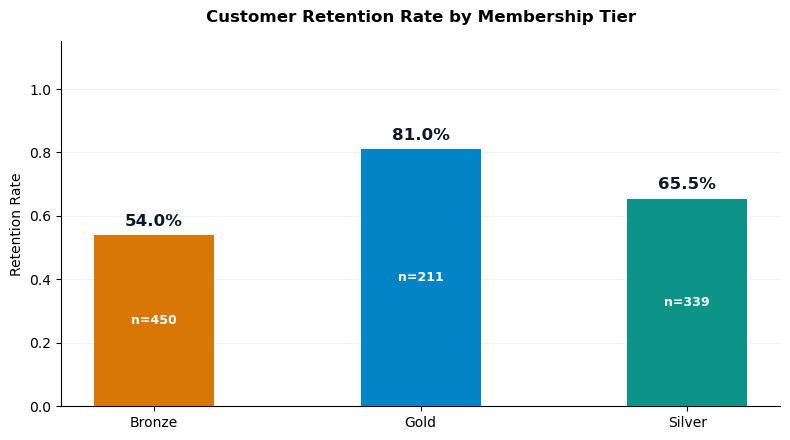

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ['#d97706', '#0284c7', '#0d9488']
bars = ax.bar(retention['Membership Type'], retention['Retention Rate'],
              color=colors, width=0.45, zorder=3)

for bar, rate, count in zip(bars, retention['Retention Rate'], retention['Total Customers']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{rate:.1%}', ha='center', va='bottom', fontsize=12,
            fontweight='bold', color='#0f172a')
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
            f'n={count}', ha='center', va='center', fontsize=9,
            color='white', fontweight='bold')

ax.set_ylabel('Retention Rate', fontsize=10)
ax.set_ylim(0, 1.15)
ax.set_title('Customer Retention Rate by Membership Tier', fontsize=12,
             fontweight='bold', pad=14)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', alpha=0.15, color='#94a3b8')
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

---
## Major Findings & Project Summary

1. Missing data in order_frequency (50 values) and total_order_value (40 values) was resolved via mean substitution.
2. Categorical features (location, membership_type, gender) were indexed into numeric vectors.
3. The Decision Tree Classifier with max_depth=5 achieved a solid baseline score on an 80/20 train-test split.
4. Gold tier members show consistently higher retention than Silver and Bronze tiers.
5. Inactivity (days_since_last_order) and satisfaction score are the primary drivers of customer churn.